<a href="https://colab.research.google.com/github/noeliafpaez/Simulations_Portfolio/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**¿Qué es la absorción de gases?**

La absorción de gases es una operación básica de la ingeniería química, que estudia la separación de uno o varios componentes de una mezcla gaseosa por disolución en un líquido. Por tanto, en esta operación se efectúa el transporte de materia del componente o componentes de la fase gaseosa solubles en el líquido absorbente, desde la fase gaseosa a la líquida.

La teoría, los datos y el problema a desarrollar en este trabajo han sido extraídos del libro "Problemas de Ingeniería Química" de Ocon Tojo. El propósito es simplemente mostrar su resolución usando Python.

**Problema:**

En el interior de un cilindro provisto de un pistón móvil se encuentran 50 Kg de agua a 20°C. En el espacio situado entre la superficie del agua y el pistón se inyectan 30 metros cúbicos (medidos a 20°C y 1 atm) de una mezcla amoniaco-aire de composición 20% en volumen de amoniaco, y se deja alcanzar el equilibrio entre las fases a 20°C y 1 atm de presión total. La tensión de vapor del agua a 20°C es 17,4 mm de Hg, y puede suponerse que la presión parcial del vapor de agua es igual a su tensión de vapor a la misma temperatura. Una vez alcanzado el equilibrio, calcúlese:

a. La presión parcial del amoniaco en la fase gaseosa (mmHg).

b. La concentración del amoniaco en la disolución, expresada en Kg NH₃/100 Kg de agua.

c. El volumen de la masa gaseosa situada entre la superficie del agua y el pistón.

Para resolver este problema el libro nos brinda datos de solubilidad del amoniaco (NH₃) en agua (H₂O), esta tabla será expresada en la siguiente celda como un DataFrame. Tener en cuenta que los valores de la fracción molar del amoniaco en la fase líquida están dados por:

                    x = (c/17) / (c/17 + 100/18)

Donde c representa la concentración molar de NH₃ (primera columna del DataFrame), y los otros valores son los pesos moleculares del NH₃ y H₂O respectivamente.

La fracción molar del NH₃ en la fase gaseosa se calcula por el cociente de la presión parcial del amoníaco y la presión total:

                        y = p_NH3 / p_total

Datos de solubilidad del amoniaco en agua, presión parcial del amoniaco en mm de Hg, fracción molar del amoniaco en la fase líquida y gaseosa respectivamente, a la presión total constante de 1 atm y 20 °C:

    Kg_NH3/100_Kg_H2O  p_NH3         x      y_20
0                60.0  945.0  0.388489  1.243421
1                50.0  686.0  0.346154  0.902632
2                40.0  470.0  0.297521  0.618421
3                30.0  298.0  0.241071  0.392105
4                25.0  227.0  0.209302  0.298684
5                20.0  166.0  0.174757  0.218421
6                15.0  114.0  0.137056  0.150000
7                10.0   69.6  0.095745  0.091579
8                 7.5   50.0  0.073569  0.065789
9                 5.0   31.7  0.050279  0.041711
10                4.0   24.9  0.040632  0.032763
11                3.0   18.2  0.030787  0.023947
12                2.0   12.0  0.020737  0.015789


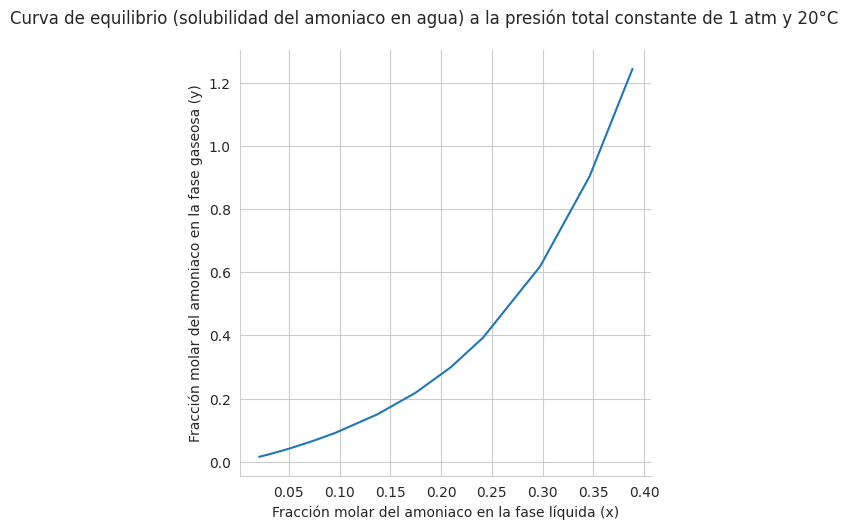

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Creando un diccionario que contenga los datos de solubilidad del NH3 en H2O expresados como Kg NH3/100 Kg H2O y las presiones parciales del NH3 en mmHg a 20 grados Celsius:
dict_20 = {"Kg_NH3/100_Kg_H2O": [60, 50, 40, 30, 25, 20, 15, 10, 7.5, 5, 4, 3, 2],
         "p_NH3": [945, 686, 470, 298, 227, 166, 114, 69.6, 50.0, 31.7, 24.9, 18.2, 12.0]}

# Transformando el diccionario en un DataFrame.
solb_20 = pd.DataFrame(dict_20)

# Calculando los valores de x, y donde x representa la fraccion molar del amoniaco en fase liquida, y la fraccion molar del amoniaco en la fase gaseosa.
for lab, row in solb_20.iterrows():
    solb_20.loc[lab, "x"] = (row["Kg_NH3/100_Kg_H2O"] / 17) / ((row["Kg_NH3/100_Kg_H2O"] / 17) + (100 / 18))
    solb_20.loc[lab, "y_20"] = row["p_NH3"] / 760

# Visualizando el DataFrame resultante con las fracciones molares de NH3 calculadas para cada solubilidad y presion parcial a 20 grados Celsius.
print("Datos de solubilidad del amoniaco en agua, presión parcial del amoniaco en mm de Hg, fracción molar del amoniaco en la fase líquida y gaseosa respectivamente, a la presión total constante de 1 atm y 20 °C:\n")
print(solb_20)

# En la siguiente figura se representa la curva de equilibrio correspondiente a las condiciones indicadas.
sns.set_style("whitegrid")

g = sns.relplot(x='x', y='y_20', data=solb_20, kind='line')
g.figure.suptitle("Curva de equilibrio (solubilidad del amoniaco en agua) a la presión total constante de 1 atm y 20°C", y=1.05)
g.set(xlabel='Fracción molar del amoniaco en la fase líquida (x)', ylabel='Fracción molar del amoniaco en la fase gaseosa (y)')
plt.show()

Ahora para determinar la cantidad de NH₃ que queda en la fase gaseosa una vez alcanzado el equilibrio, se debe hacer un balance entre los datos de las condiciones iniciales y finales. Los moles (n) iniciales del NH₃ y del aire vienen dados por las siguientes ecuaciones:

1) n_NH3_inicial = (p_NH3 * V) / (R * T) = (0.2 * 30000) / (0.082 * 293) = 249.7

2) n_aire_inicial = (p_aire * V) / (R * T) = (0.8 * 30000) / (0.082 * 293) = 998.9

Donde:

V: Volumen de la mezcla amoniaco-aire.

R: Constante de los gases ideales.

T: Temperatura de la mezcla en Kelvin.

Las condiciones finales se calcularán a partir de la siguiente relación:

presion_total = presion_parcial_H2O + presion_parcial_aire +  presion_parcial_NH3

     760 = 17.4 + presion_parcial_aire + presion_parcial_NH3

      3. presion_parcial_aire + presion_parcial_NH3 = 742.6

Por otra parte, haciendo un balance entre las condiciones iniciales y finales:

     4. (n_aire * R * T) / p_aire = (n_NH3 * R * T) / p_NH3

Los moles de aire son constantes, por tanto, reemplazamos su valor calculado en la ecuación 2 en 4; asimismo, usamos la presion_parcial_aire de la ecuación 3 en 4, obteniendo la siguiente relación:

       5. n_NH3_final = (p_NH3 / (742,6 - p_NH3)) * 998.9

La cantidad de amoniaco que pasa al agua, en gramos, vendrá dada por:

  50 Kg H2O * c Kg NH3 / 100 Kg H2O = 0.5 * c Kg NH3 = 500 * c g NH3

Por consiguiente:

     500 * c = 17 * [249.7 - ((p_NH3 * 998.9) / (742.6 - p_NH3))]

Lo que nos interesa es la presión parcial del NH₃ en la fase gaseosa una vez alcanzado el equilibrio. Para esto, vamos a despejar p_NH3 de la anterior relación, pero como no conocemos tampoco la concentración de NH₃, daremos valores arbitrarios a c. Esto nos generará otra curva específica para este sistema; la intersección de esta curva con la del equilibrio (obtenida del DataFrame solb_20) nos dará el valor de p_NH3 que estamos buscando.

Rango de valores asumidos para las concentraciones finales de amoniaco en la disolución: [1, 2, 3, 4, 5, 6, 7, 8]

Valores de las presiones parciales de amoniaco en el sistema una vez alcanzado el equilibrio, calculadas a partir de las concentraciones asumidas anteriormente: [134.201, 119.174, 103.386, 86.778, 69.284, 50.831, 31.338, 10.715]


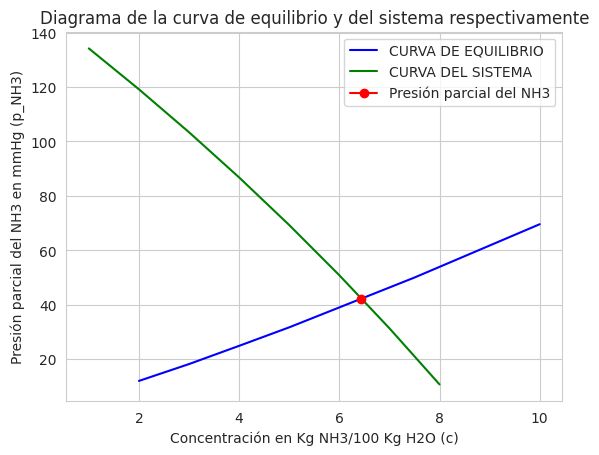

a. La intersección con la curva de equilibrio da: (6.440, 42.244) y, por tanto, la presión parcial del amoniaco en la fase gasesa es: 42.24 mmHg.

b. La concentración del amoniaco en la disolución es: 6.44 Kg de NH3 por 100 Kg de H2O.

c. El volumen de la masa gaseosa situada entre la superficie del agua y el pistón es: 26043.45 litros.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import LineString

# Copiando el DataFrame creado anteriormente.
dict_20 = {"Kg_NH3/100_Kg_H2O": [60, 50, 40, 30, 25, 20, 15, 10, 7.5, 5, 4, 3, 2],
         "p_NH3": [945, 686, 470, 298, 227, 166, 114, 69.6, 50.0, 31.7, 24.9, 18.2, 12.0]}

solb_20 = pd.DataFrame(dict_20)

for lab, row in solb_20.iterrows():
    solb_20.loc[lab, "x"] = (row["Kg_NH3/100_Kg_H2O"] / 17) / ((row["Kg_NH3/100_Kg_H2O"] / 17) + (100 / 18))
    solb_20.loc[lab, "y_20"] = row["p_NH3"] / 760

# Del DataFrame se extraen los datos necesarios para graficar la curva de equilibrio.
c1 = solb_20["Kg_NH3/100_Kg_H2O"]
p1 = solb_20["p_NH3"]

# Generando valores para la concentracion de amoniaco en el sistema (c2), con el fin de usarlos en el calculo de las presiones parciales (p2).
c2 = list(range(1, 9))
print(f"Rango de valores asumidos para las concentraciones finales de amoniaco en la disolución: {c2}\n")

"""De la ultima ecuacion al despejar p_NH3 se obtiene la siguiente relacion: p_NH3 = (185.65 - 21.847292 * c)/(1 + 0.250 - 0.02942 * c), que sera empleada para el calculo de cada valor de p2"""

p2 = [round((185.65 - 21.847292 * c)/(1 + 0.250 - 0.02942 * c), 3) for c in c2]
print(f"Valores de las presiones parciales de amoniaco en el sistema una vez alcanzado el equilibrio, calculadas a partir de las concentraciones asumidas anteriormente: {p2}")

"""No se tomaron valores para la concentracion de c2 mayores a 8 porque los valores de p2 se vuelven negativos y esto no es posible."""

# Creando una lista de puntos (c1, p1) que formaran la primera curva: la curva de equilibrio o solubilidad a 20 grados Celsius.
solb_20 = list(zip(c1, p1))

# Creando un lista de puntos (c2, p2) que formaran la segunda curva: la curva de operacion.
c_op = list(zip(c2, p2))

# Creando las dos lineas (curvas) a partir de los puntos formados.
line1 = LineString(solb_20)
line2 = LineString(c_op)

# Encontrando la presion parcial del amoniaco en la fase gaseosa usando el metodo de intersection() de la libreria Shapely.
intersection = line1.intersection(line2)

# Representando estas curvas en un diagrama, para tener una mejor aproximacion visual de la interseccion voy a limitar los valores de la curva de equilibrio.
c1_lim = c1[(c1 <= 10) & (p1 <= 140)]
p1_lim = p1[(c1 <= 10) & (p1 <= 140)]

fig, ax = plt.subplots()
ax.plot(c1_lim, p1_lim, label="CURVA DE EQUILIBRIO", color="blue")
ax.plot(c2, p2, label="CURVA DEL SISTEMA", color="green")
ax.plot(intersection.x, intersection.y, label="Presión parcial del NH3", color="red", marker="o")
plt.title("Diagrama de la curva de equilibrio y del sistema respectivamente")
plt.xlabel("Concentración en Kg NH3/100 Kg H2O (c)")
plt.ylabel("Presión parcial del NH3 en mmHg (p_NH3)")
plt.legend()
ax.grid(True)
plt.show()

print(f"a. La intersección con la curva de equilibrio da: ({intersection.x:.3f}, {intersection.y:.3f}) y, por tanto, la presión parcial del amoniaco en la fase gasesa es: {intersection.y:.2f} mmHg.\n")
print(f"b. La concentración del amoniaco en la disolución es: {intersection.x:.2f} Kg de NH3 por 100 Kg de H2O.\n")

# Calculando el volumen de la masa gaseosa usando la ecuacion general de los gases ideales. De la ecuacion 3 obtengo la presion parcial del aire.
# CORRECCIÓN: No se puede usar formato dentro de una expresión matemática. Se debe calcular el valor y luego formatear si se desea imprimir.
p_aire = 760 - (intersection.y + 17.4)

Volumen = (998.9 * 0.082 * 293) / (p_aire/760)

print(f"c. El volumen de la masa gaseosa situada entre la superficie del agua y el pistón es: {round(Volumen, 2)} litros.")